# Split test: full K-fold members, or one base model fine-tuned on more folds?

Two ways to train the ensemble with `znn.train_from_catalog`, both with K-fold data cuts (member k validates on fold k and trains on the others), every member on its own noise realization of the training photometry, and the pop-cosmos start:

| ensemble | members | how each member is trained |
|---|---|---|
| `kfold5` | 5 | in full from the pop-cosmos start, up to `EPOCHS` at the Adam default learning rate |
| `frombase_kfold10` | 10 | a copy of one base model (trained first on all the objects with the photometry as given) fine-tuned on its fold at `FINETUNE_LR` for at most `FINETUNE_EPOCHS` |

`from_base` is meant to be cheaper per member, so it can afford more of them; the question is whether 10 fine-tuned members score as well as 5 fully trained ones, and at what training cost. Note that the base model has seen every member's validation fold, so the fine-tuned members' early stopping is not on unseen data.

The saved `baseline` ensemble (5 K-fold members from the 5 pop-cosmos starts, catalogue photometry, no noise realizations) is re-evaluated as a reference. The previous split test (commit f881508) found that retraining with identical settings moves the scatter by about 5% and KS by about 15%: treat differences smaller than that as noise. That test also found that K-fold cuts beat one shared cut, and that one pop-cosmos start is as good as five.

Everything is on the configuration that degraded most (task set 3, cardinal, 10yr), scored on the same held-out objects (the `VAL_FRAC`, `SEED` split of the task-set notebooks, never used in training) and predicted the same way: `znn.predict_from_catalog` with `N_SAMPLES` noise draws from the same seed, giving a Gaussian p(z) per object. Besides the challenge metrics, the table gives each ensemble's training time and splits the p(z) width into the members' disagreement ("model σ") and the spread over noise draws ("photometric σ").

Run this from the repo root on NERSC with the `qp` conda env as the kernel. Trained models, their training times and the predictions are saved in `TEST_DIR`, so a rerun skips what is done.

## Configuration

In [1]:
import os

from rail.utils.path_utils import find_rail_file

import znn  # run from the repo root so this picks up the local source

# the configuration that degraded most in the noisytrain run
TASKSET, SIM, SCENARIO = 3, "cardinal", "10yr"
DATA_DIR = "../pz_data_challenge/scripts/public"  # as in the task-set notebooks

# Saved ensembles to re-evaluate: name -> candidate OUT_DIRs (the first that has the model file is used)
SAVED = {
    "baseline": ["outputs/znn_pretrained_popcosmos"],
}
# Ensembles trained here: name -> znn.train_from_catalog settings
TRAIN = {
    "kfold5": dict(N_MEMBERS=5, from_base=False),
    "frombase_kfold10": dict(N_MEMBERS=10, from_base=True),
}
TEST_DIR = f"outputs/frombase_test_taskset_{TASKSET}_{SIM}_{SCENARIO}"  # models trained here, their times, predictions

# as in the task-set notebooks
PRETRAINING = "popcosmos"
EPOCHS = 100  # max epochs per fully trained member, and of the base model
FINETUNE_EPOCHS = 10  # max epochs of each fine-tuned member
FINETUNE_LR = 1e-4  # fine-tuning learning rate (full training is at the Adam default, 1e-3)
VAL_FRAC = 0.2  # the held-out split (and the base model's early-stopping fraction)
SEED = 42
NOISE_SEED = 42  # seed of the training noise realizations
# as in pz_challenge_results.ipynb
N_SAMPLES = 50
PREDICT_SEED = 42

FILTER_DIR = find_rail_file("examples_data/estimation_data/data/FILTER")
BANDS = {
    "u": ("mag_u_lsst", f"{FILTER_DIR}/DC2LSST_u.res"),
    "g": ("mag_g_lsst", f"{FILTER_DIR}/DC2LSST_g.res"),
    "r": ("mag_r_lsst", f"{FILTER_DIR}/DC2LSST_r.res"),
    "i": ("mag_i_lsst", f"{FILTER_DIR}/DC2LSST_i.res"),
    "z": ("mag_z_lsst", f"{FILTER_DIR}/DC2LSST_z.res"),
    "y": ("mag_y_lsst", f"{FILTER_DIR}/DC2LSST_y.res"),
    "Y": ("mag_Y_roman", f"{FILTER_DIR}/roman_Y106.res"),
    "J": ("mag_J_roman", f"{FILTER_DIR}/roman_J129.res"),
    "H": ("mag_H_roman", f"{FILTER_DIR}/roman_H158.res"),
}
REF_BAND = "i"
FEATURE_CONFIG = znn.DEFAULT_FEATURE_CONFIG
ERRORS = {col: f"{col}_err" for col, _ in BANDS.values()}

I0000 00:00:1793220812.592288  803210 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import qp
from qp.metrics.pit import PIT
from sklearn.model_selection import train_test_split

from pz_data_challenge import scoring

os.makedirs(TEST_DIR, exist_ok=True)
MODEL_NAME = f"pz_challenge_taskset_{TASKSET}_{SIM}_pz_model_{SCENARIO}.pkl"

SPEC_SURVEYS = ["DEEP2_LSST", "DESI_BGS", "DESI_ELG_LOP", "DESI_LRG", "VVDSf02", "zCOSMOS"]


def reference_redshifts(train):
    # Reference redshift per training object, and the held-out subsets to score (as in pz_challenge_results.ipynb).
    z_spec = train["redshift"].to_numpy()
    if "COSMOS" not in train:  # task sets 1 and 2
        subsets = {"all": np.ones(len(train), dtype=bool)}
        if (train["mag_i_lsst"] < 23.5).all():
            return z_spec, subsets  # task set 1
        return z_spec, subsets | {"i > 23": train["mag_i_lsst"].to_numpy() > 23}  # task set 2

    is_spec = train[[c for c in SPEC_SURVEYS if c in train]].astype(bool).any(axis=1).to_numpy()
    is_cosmos_only = train["COSMOS"].astype(bool).to_numpy() & ~is_spec
    z_ref = np.where(is_cosmos_only, train["redshift_manyband"].to_numpy(), z_spec)
    assert np.isfinite(z_ref).all()
    return z_ref, {"all": np.ones(len(train), dtype=bool), "spec": is_spec, "COSMOS-only": is_cosmos_only}


train = znn.read_catalog(os.path.join(DATA_DIR, f"pz_challenge_taskset_{TASKSET}_{SIM}_training_{SCENARIO}.hdf5"))
z_ref, subsets = reference_redshifts(train)
idx_fit, idx_val = train_test_split(np.arange(len(train)), test_size=VAL_FRAC, random_state=SEED)
val = train.iloc[idx_val]
print(f"task set {TASKSET} {SIM} {SCENARIO}: {len(idx_fit)} objects to train on, {len(idx_val)} held out")

model_files = {}
for name, candidates in SAVED.items():
    found = [d for d in candidates if os.path.exists(os.path.join(d, MODEL_NAME))]
    assert found, f"no saved {name} model {MODEL_NAME} in {candidates}"
    model_files[name] = os.path.join(found[0], MODEL_NAME)
    print(f"{name}: {model_files[name]}")

task set 3 cardinal 10yr: 80000 objects to train on, 20000 held out
baseline: outputs/znn_pretrained_popcosmos/pz_challenge_taskset_3_cardinal_pz_model_10yr.pkl


## Train

Each ensemble in `TRAIN` is trained on the fit split with `znn.train_from_catalog` and saved in `TEST_DIR`, with its wall-clock training time. An ensemble already saved there is loaded instead.


==================== kfold5: {'N_MEMBERS': 5, 'from_base': False} ====================


I0000 00:00:1793220899.776081  803210 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 38478 MB memory:  -> device: 0, name: NVIDIA A100-SXM4-40GB, pci bus id: 0000:03:00.0, compute capability: 8.0
I0000 00:00:1793220899.785972  803210 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 38478 MB memory:  -> device: 1, name: NVIDIA A100-SXM4-40GB, pci bus id: 0000:41:00.0, compute capability: 8.0
I0000 00:00:1793220899.796819  803210 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:2 with 38478 MB memory:  -> device: 2, name: NVIDIA A100-SXM4-40GB, pci bus id: 0000:82:00.0, compute capability: 8.0
I0000 00:00:1793220899.806773  803210 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:3 with 38478 MB memory:  -> device: 3, name: NVIDIA A100-SXM4-40GB, pci bus id: 0000:c1:00.0, compute capability: 8.0



--- Member 1/5 (its own noise realization) ---
Epoch 1/100


I0000 00:00:1793220903.522673  803712 service.cc:153] XLA service 0x7f7048036550 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793220903.522693  803712 service.cc:161]   StreamExecutor [0]: NVIDIA A100-SXM4-40GB, Compute Capability 8.0 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793220903.522701  803712 service.cc:161]   StreamExecutor [1]: NVIDIA A100-SXM4-40GB, Compute Capability 8.0 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793220903.522704  803712 service.cc:161]   StreamExecutor [2]: NVIDIA A100-SXM4-40GB, Compute Capability 8.0 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793220903.522707  803712 service.cc:161]   StreamExecutor [3]: NVIDIA A100-SXM4-40GB, Compute Capability 8.0 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793220903.556741  803712 dump_mlir_util.cc:269] disabling MLIR crash repro

250/250 - 33s - 131ms/step - loss: 0.0062 - val_loss: 0.0037 - learning_rate: 0.0010
Epoch 2/100
250/250 - 1s - 3ms/step - loss: 0.0054 - val_loss: 0.0036 - learning_rate: 0.0010
Epoch 3/100
250/250 - 1s - 3ms/step - loss: 0.0052 - val_loss: 0.0036 - learning_rate: 0.0010
Epoch 4/100
250/250 - 1s - 3ms/step - loss: 0.0051 - val_loss: 0.0034 - learning_rate: 0.0010
Epoch 5/100
250/250 - 1s - 3ms/step - loss: 0.0050 - val_loss: 0.0034 - learning_rate: 0.0010
Epoch 6/100
250/250 - 1s - 3ms/step - loss: 0.0049 - val_loss: 0.0035 - learning_rate: 0.0010
Epoch 7/100

Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
250/250 - 1s - 3ms/step - loss: 0.0049 - val_loss: 0.0037 - learning_rate: 0.0010
Epoch 8/100
250/250 - 1s - 3ms/step - loss: 0.0047 - val_loss: 0.0033 - learning_rate: 5.0000e-04
Epoch 9/100
250/250 - 1s - 3ms/step - loss: 0.0047 - val_loss: 0.0033 - learning_rate: 5.0000e-04
Epoch 10/100
250/250 - 1s - 3ms/step - loss: 0.0046 - val_loss: 0.0033 - learn

...

250/250 - 5s - 21ms/step - loss: 0.0060 - val_loss: 0.0049 - learning_rate: 0.0010
Epoch 2/100
250/250 - 1s - 3ms/step - loss: 0.0050 - val_loss: 0.0048 - learning_rate: 0.0010
Epoch 3/100
250/250 - 1s - 3ms/step - loss: 0.0048 - val_loss: 0.0048 - learning_rate: 0.0010
Epoch 4/100
250/250 - 1s - 3ms/step - loss: 0.0047 - val_loss: 0.0047 - learning_rate: 0.0010
Epoch 5/100
250/250 - 1s - 3ms/step - loss: 0.0047 - val_loss: 0.0047 - learning_rate: 0.0010
Epoch 6/100
250/250 - 1s - 3ms/step - loss: 0.0046 - val_loss: 0.0046 - learning_rate: 0.0010
Epoch 7/100
250/250 - 1s - 3ms/step - loss: 0.0046 - val_loss: 0.0046 - learning_rate: 0.0010
Epoch 8/100

Epoch 8: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
250/250 - 1s - 3ms/step - loss: 0.0045 - val_loss: 0.0048 - learning_rate: 0.0010
Epoch 9/100
250/250 - 1s - 3ms/step - loss: 0.0044 - val_loss: 0.0045 - learning_rate: 5.0000e-04
Epoch 10/100
250/250 - 1s - 3ms/step - loss: 0.0043 - val_loss: 0.0045 - learning_ra

I0000 00:00:1793220974.567829  803712 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_50584__.37


250/250 - 5s - 20ms/step - loss: 0.0058 - val_loss: 0.0053 - learning_rate: 0.0010
Epoch 2/100
250/250 - 1s - 3ms/step - loss: 0.0050 - val_loss: 0.0050 - learning_rate: 0.0010
Epoch 3/100
250/250 - 1s - 3ms/step - loss: 0.0048 - val_loss: 0.0050 - learning_rate: 0.0010
Epoch 4/100
250/250 - 1s - 3ms/step - loss: 0.0046 - val_loss: 0.0050 - learning_rate: 0.0010
Epoch 5/100

Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
250/250 - 1s - 3ms/step - loss: 0.0046 - val_loss: 0.0052 - learning_rate: 0.0010
Epoch 6/100
250/250 - 1s - 3ms/step - loss: 0.0044 - val_loss: 0.0049 - learning_rate: 5.0000e-04
Epoch 7/100
250/250 - 1s - 3ms/step - loss: 0.0043 - val_loss: 0.0050 - learning_rate: 5.0000e-04
Epoch 8/100
250/250 - 1s - 3ms/step - loss: 0.0043 - val_loss: 0.0049 - learning_rate: 5.0000e-04
Epoch 9/100

Epoch 9: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
250/250 - 1s - 3ms/step - loss: 0.0043 - val_loss: 0.0049 - learning_rate: 5.0000

I0000 00:00:1793220990.996117  803711 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_69322__.37


250/250 - 5s - 21ms/step - loss: 0.0059 - val_loss: 0.0050 - learning_rate: 0.0010
Epoch 2/100
250/250 - 1s - 3ms/step - loss: 0.0050 - val_loss: 0.0050 - learning_rate: 0.0010
Epoch 3/100
250/250 - 1s - 3ms/step - loss: 0.0048 - val_loss: 0.0048 - learning_rate: 0.0010
Epoch 4/100
250/250 - 1s - 3ms/step - loss: 0.0047 - val_loss: 0.0050 - learning_rate: 0.0010
Epoch 5/100
250/250 - 1s - 3ms/step - loss: 0.0046 - val_loss: 0.0048 - learning_rate: 0.0010
Epoch 6/100

Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
250/250 - 1s - 3ms/step - loss: 0.0046 - val_loss: 0.0049 - learning_rate: 0.0010
Epoch 7/100
250/250 - 1s - 3ms/step - loss: 0.0044 - val_loss: 0.0048 - learning_rate: 5.0000e-04
Epoch 8/100
250/250 - 1s - 3ms/step - loss: 0.0043 - val_loss: 0.0047 - learning_rate: 5.0000e-04
Epoch 9/100
250/250 - 1s - 3ms/step - loss: 0.0042 - val_loss: 0.0049 - learning_rate: 5.0000e-04
Epoch 10/100
250/250 - 1s - 3ms/step - loss: 0.0042 - val_loss: 0.0049 - lea

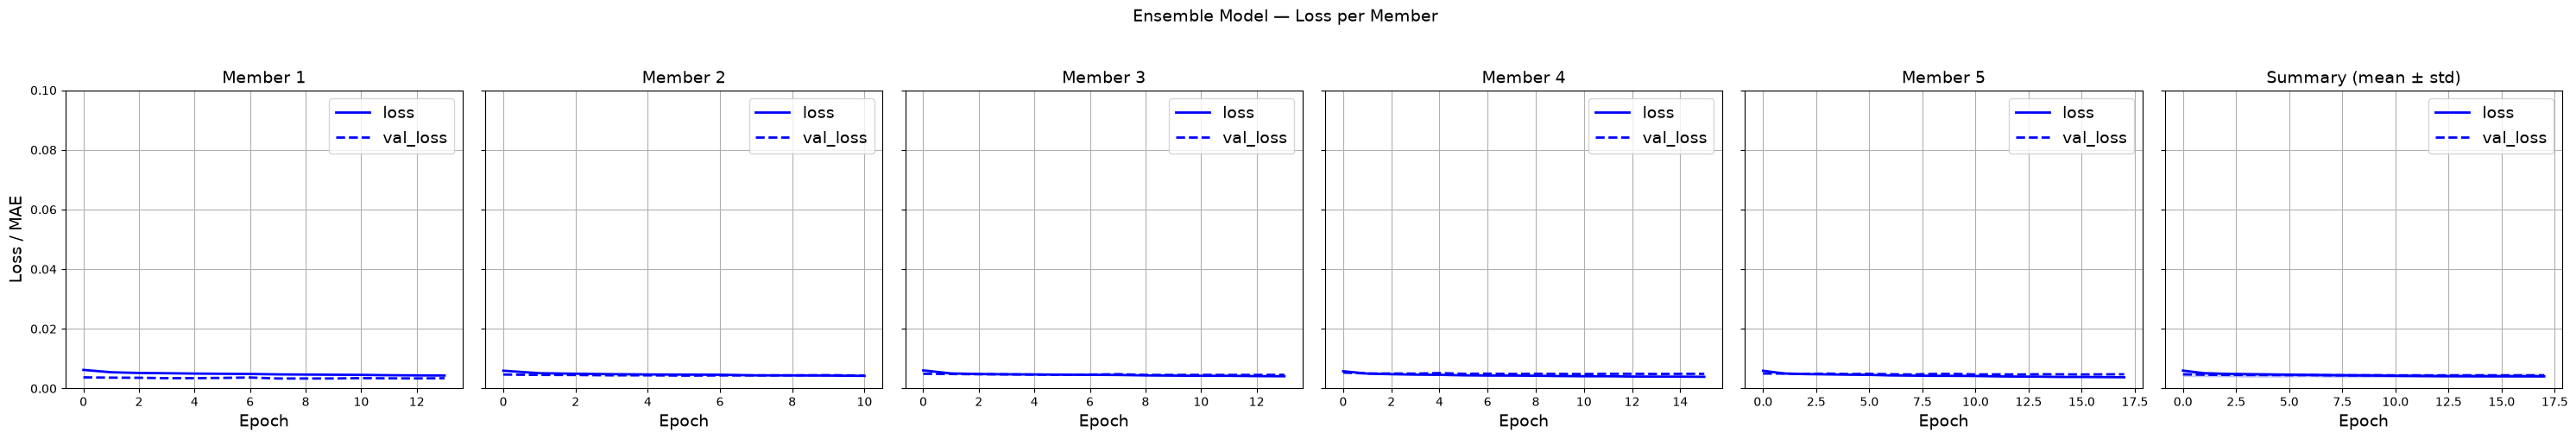

<Figure size 640x480 with 0 Axes>


==================== frombase_kfold10: {'N_MEMBERS': 10, 'from_base': True} ====================

=== Base model, on all objects with the photometry as given ===
Epoch 1/100


I0000 00:00:1793221014.209578  803713 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_90557__.37


250/250 - 5s - 21ms/step - loss: 0.0058 - val_loss: 0.0035 - learning_rate: 0.0010
Epoch 2/100
250/250 - 1s - 3ms/step - loss: 0.0051 - val_loss: 0.0032 - learning_rate: 0.0010
Epoch 3/100
250/250 - 1s - 3ms/step - loss: 0.0049 - val_loss: 0.0036 - learning_rate: 0.0010
Epoch 4/100
250/250 - 1s - 3ms/step - loss: 0.0048 - val_loss: 0.0033 - learning_rate: 0.0010
Epoch 5/100

Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
250/250 - 1s - 3ms/step - loss: 0.0047 - val_loss: 0.0033 - learning_rate: 0.0010
Epoch 6/100
250/250 - 1s - 3ms/step - loss: 0.0046 - val_loss: 0.0030 - learning_rate: 5.0000e-04
Epoch 7/100
250/250 - 1s - 3ms/step - loss: 0.0045 - val_loss: 0.0030 - learning_rate: 5.0000e-04
Epoch 8/100
250/250 - 1s - 3ms/step - loss: 0.0045 - val_loss: 0.0032 - learning_rate: 5.0000e-04
Epoch 9/100

Epoch 9: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
250/250 - 1s - 3ms/step - loss: 0.0045 - val_loss: 0.0031 - learning_rate: 5.0000

I0000 00:00:1793221032.989319  803711 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_112202__.38
I0000 00:00:1793221035.802634  803710 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_112202__.38
I0000 00:00:1793221037.921296  803710 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1793221041.069914  803710 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1793221043.241469  803710 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a

...

282/282 - 7s - 26ms/step - loss: 0.0046 - val_loss: 0.0042 - learning_rate: 1.0000e-04
Epoch 2/10
282/282 - 1s - 3ms/step - loss: 0.0045 - val_loss: 0.0042 - learning_rate: 1.0000e-04
Epoch 3/10
282/282 - 1s - 3ms/step - loss: 0.0045 - val_loss: 0.0042 - learning_rate: 1.0000e-04
Epoch 4/10

Epoch 4: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
282/282 - 1s - 3ms/step - loss: 0.0044 - val_loss: 0.0042 - learning_rate: 1.0000e-04
Epoch 5/10
282/282 - 1s - 3ms/step - loss: 0.0044 - val_loss: 0.0042 - learning_rate: 5.0000e-05
Epoch 6/10
282/282 - 1s - 3ms/step - loss: 0.0044 - val_loss: 0.0042 - learning_rate: 5.0000e-05

--- Member 9/10 (its own noise realization) ---
Epoch 1/10


I0000 00:00:1793221154.100858  803709 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_202016__.38
I0000 00:00:1793221156.411360  803711 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_202016__.38


282/282 - 7s - 25ms/step - loss: 0.0046 - val_loss: 0.0041 - learning_rate: 1.0000e-04
Epoch 2/10
282/282 - 1s - 3ms/step - loss: 0.0045 - val_loss: 0.0041 - learning_rate: 1.0000e-04
Epoch 3/10
282/282 - 1s - 3ms/step - loss: 0.0045 - val_loss: 0.0041 - learning_rate: 1.0000e-04
Epoch 4/10

Epoch 4: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
282/282 - 1s - 3ms/step - loss: 0.0044 - val_loss: 0.0041 - learning_rate: 1.0000e-04
Epoch 5/10
282/282 - 1s - 3ms/step - loss: 0.0044 - val_loss: 0.0041 - learning_rate: 5.0000e-05
Epoch 6/10
282/282 - 1s - 3ms/step - loss: 0.0043 - val_loss: 0.0041 - learning_rate: 5.0000e-05
Epoch 7/10

Epoch 7: ReduceLROnPlateau reducing learning rate to 2.499999936844688e-05.
282/282 - 1s - 3ms/step - loss: 0.0043 - val_loss: 0.0041 - learning_rate: 5.0000e-05
Epoch 8/10
282/282 - 1s - 3ms/step - loss: 0.0043 - val_loss: 0.0041 - learning_rate: 2.5000e-05
Epoch 9/10
282/282 - 1s - 3ms/step - loss: 0.0043 - val_loss: 0.0041 - learning_

I0000 00:00:1793221167.621398  803712 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_213973__.38
I0000 00:00:1793221169.944045  803710 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_213973__.38


282/282 - 7s - 25ms/step - loss: 0.0046 - val_loss: 0.0047 - learning_rate: 1.0000e-04
Epoch 2/10
282/282 - 1s - 3ms/step - loss: 0.0045 - val_loss: 0.0047 - learning_rate: 1.0000e-04
Epoch 3/10
282/282 - 1s - 3ms/step - loss: 0.0044 - val_loss: 0.0047 - learning_rate: 1.0000e-04
Epoch 4/10

Epoch 4: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
282/282 - 1s - 3ms/step - loss: 0.0044 - val_loss: 0.0047 - learning_rate: 1.0000e-04
Epoch 5/10
282/282 - 1s - 3ms/step - loss: 0.0043 - val_loss: 0.0047 - learning_rate: 5.0000e-05
Epoch 6/10
282/282 - 1s - 3ms/step - loss: 0.0043 - val_loss: 0.0046 - learning_rate: 5.0000e-05
Epoch 7/10

Epoch 7: ReduceLROnPlateau reducing learning rate to 2.499999936844688e-05.
282/282 - 1s - 3ms/step - loss: 0.0043 - val_loss: 0.0047 - learning_rate: 5.0000e-05
Epoch 8/10
282/282 - 1s - 3ms/step - loss: 0.0043 - val_loss: 0.0046 - learning_rate: 2.5000e-05
Epoch 9/10
282/282 - 1s - 3ms/step - loss: 0.0043 - val_loss: 0.0046 - learning_

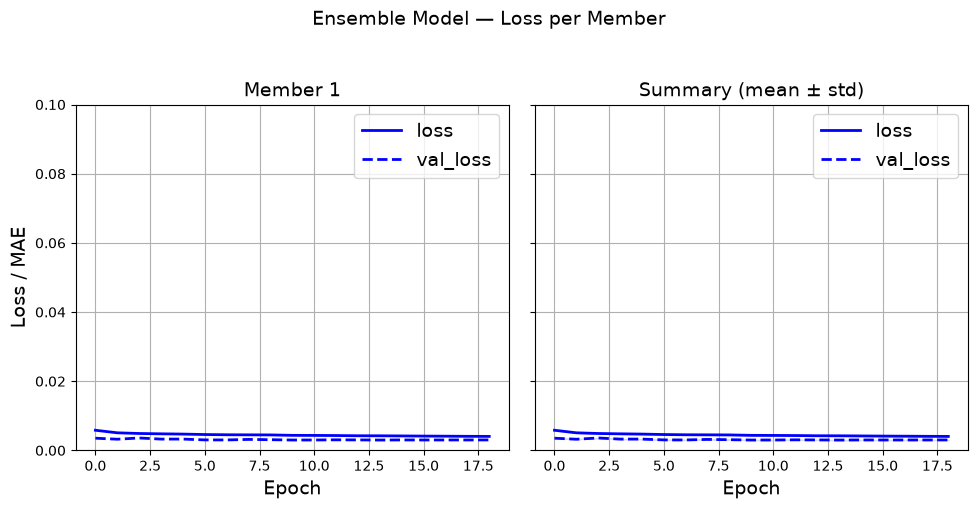

<Figure size 640x480 with 0 Axes>

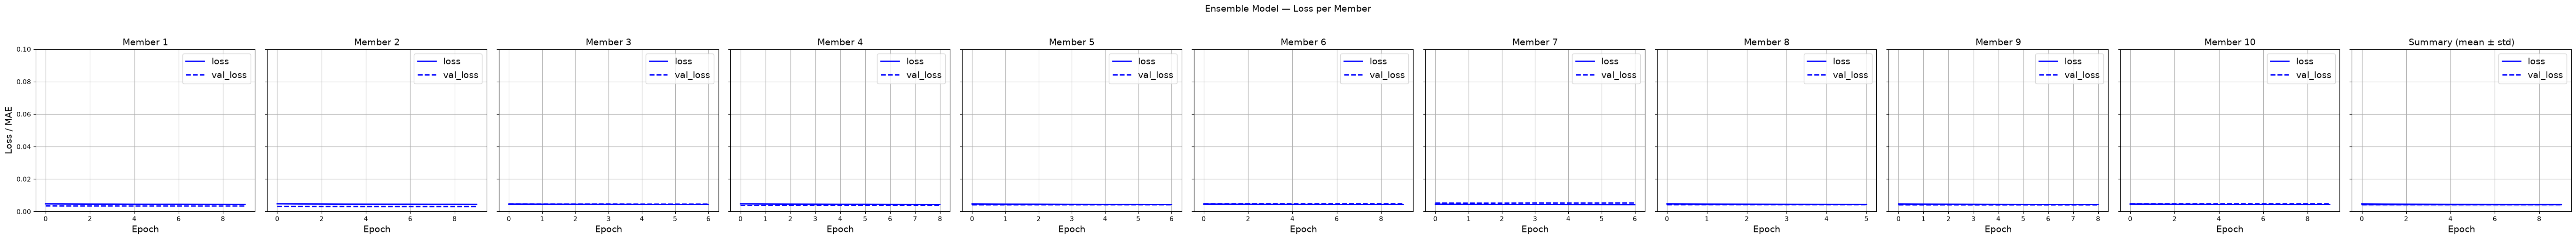

<Figure size 640x480 with 0 Axes>

In [3]:
train_minutes = {}
for name, settings in TRAIN.items():
    model_files[name] = os.path.join(TEST_DIR, f"{name}_{MODEL_NAME}")
    time_file = os.path.join(TEST_DIR, f"{name}_train_time.json")
    if os.path.exists(model_files[name]) and os.path.exists(time_file):
        train_minutes[name] = json.load(open(time_file))["minutes"]
        print(f"{name}: already trained ({train_minutes[name]:.1f} min), {model_files[name]}")
        continue
    print(f"\n==================== {name}: {settings} ====================")
    start = time.time()
    trained_models, histories, base_history = znn.train_from_catalog(
        znn.build_model, train.iloc[idx_fit], z_ref[idx_fit], BANDS, REF_BAND, FEATURE_CONFIG, errors=ERRORS,
        rng=np.random.default_rng(NOISE_SEED), EPOCHS=EPOCHS, FINETUNE_EPOCHS=FINETUNE_EPOCHS, FINETUNE_LR=FINETUNE_LR,
        random_state=SEED, pretraining=PRETRAINING, **settings,
    )
    train_minutes[name] = (time.time() - start) / 60
    json.dump({"minutes": train_minutes[name]}, open(time_file, "w"))
    znn.save_ensemble_file(model_files[name], trained_models, BANDS, REF_BAND, FEATURE_CONFIG)
    print(f"{name}: trained in {train_minutes[name]:.1f} min")

    if base_history is not None:
        znn.plot_ensemble_losses([base_history], ylim=(0, 0.1))
        plt.suptitle(f"{name}: base model", y=1.08)
        plt.show()
    znn.plot_ensemble_losses(histories, ylim=(0, 0.1))
    plt.suptitle(name, y=1.08)
    plt.show()

## Predict the held-out objects

Every ensemble with the same `N_SAMPLES` noise draws (same seed). Cached in `TEST_DIR`.

In [4]:
def heldout_predictions(name):
    # Per held-out object: p(z) mean and std, and the std split into members' disagreement and noise draws.
    cache = os.path.join(TEST_DIR, f"heldout_{name}.npz")
    if os.path.exists(cache):
        return dict(np.load(cache))
    trained_models, features = znn.load_ensemble_file(model_files[name])
    errors = {col: f"{col}_err" for col, _ in features["bands"].values()}
    pz, components = znn.predict_from_catalog(
        trained_models, val, **features, errors=errors, n_samples=N_SAMPLES, rng=np.random.default_rng(PREDICT_SEED),
        return_components=True,
    )
    out = {
        "mean": np.squeeze(pz.mean()),
        "std": np.squeeze(pz.std()),
        "model_std": components["model"],
        "photometric_std": components["photometric"],
    }
    np.savez(cache, **out)
    return out


ARMS = list(SAVED) + list(TRAIN)
preds = {}
for name in ARMS:
    print("held-out predictions:", name)
    preds[name] = heldout_predictions(name)

held-out predictions: baseline
held-out predictions: kfold5
held-out predictions: frombase_kfold10


## Scores

The challenge's seven metrics (as in `pz_challenge_results.ipynb`, with the mean as the point estimate) and their tier points, per ensemble and held-out subset, plus:
- `width/scatter`: median p(z) σ/(1+z) over the biweight scatter; 1 for p(z)s as wide as the actual errors, below 1 for overconfident ones;
- `model σ`, `photometric σ`: median of the two parts of the p(z) σ (they add in quadrature). `model σ` measures how different the members are;
- `pit_outlier_direct`: the PIT outlier rate computed directly (the scored `outlier` comes from a spline fit that breaks down when PIT piles up at 0 or 1).

Lower is better for all metrics except the points. Remember the run-to-run noise of about 5% in scatter and 15% in KS.

In [5]:
def scores(z, d, m):
    dz = (d["mean"][m] - z[m]) / (1 + z[m])
    bias, _, scatter, _, abs_outlier_rate = znn.get_biweight_mean_sigma_outlier(dz)
    pz = qp.Ensemble(qp.stats.norm, data={"loc": d["mean"][m, None], "scale": d["std"][m, None]})
    pit = PIT(pz, z[m])
    values = {
        "mean": bias,
        "std": scatter,
        "abs_outlier_rate": abs_outlier_rate,
        "ks": pit.evaluate_PIT_KS().statistic,
        "CvM": pit.evaluate_PIT_CvM().statistic,
        "ksamp": pit.evaluate_PIT_anderson_ksamp().statistic,
        "outlier": pit.evaluate_PIT_outlier_rate(),
    }
    points = sum(lo <= float(values[k]) <= hi for k, ranges in scoring.metric_dict.items() for lo, hi in ranges)
    extra = {
        "pit_outlier_direct": np.mean((pit.pit_samps < 0.0001) | (pit.pit_samps > 0.9999)),
        "width/scatter": np.median(d["std"][m] / (1 + z[m])) / scatter,
        "model σ": np.median(d["model_std"][m]),
        "photometric σ": np.median(d["photometric_std"][m]),
        "points": points,
    }
    return values | extra, pit.pit_samps


z_val = z_ref[idx_val]
rows, pits = {}, {}
for name in ARMS:
    for subset, mask in subsets.items():
        rows[(subset, name)], pits[(subset, name)] = scores(z_val, preds[name], mask[idx_val])

table = pd.DataFrame(rows).T
table.index.names = ["subset", "ensemble"]
n_max = sum(len(r) for r in scoring.metric_dict.values())
print(f"points out of {n_max}")
table.round(4)

/global/homes/j/jaimerz/envs/pzdc/lib/python3.12/site-packages/qp/metrics/array_metrics.py:27: UserWarning: Parameter `variant` has been introduced to replace `midrank`; `midrank` will be removed in SciPy 1.19.0. Specify `variant` to silence this warning. Note that the returned object will no longer be unpackable as a tuple, and `critical_values` will be omitted.
  return stats.anderson_ksamp([p_random_variables, q_random_variables], **kwargs)
/global/homes/j/jaimerz/envs/pzdc/lib/python3.12/site-packages/qp/metrics/array_metrics.py:27: UserWarning: p-value floored: true value smaller than 0.001. Consider specifying `method` (e.g. `method=stats.PermutationMethod()`.)
  return stats.anderson_ksamp([p_random_variables, q_random_variables], **kwargs)


points out of 21


,,mean,std,abs_outlier_rate,ks,CvM,ksamp,outlier,pit_outlier_direct,width/scatter,model σ,photometric σ,points
subset,ensemble,,,,,,,,,,,,
all,baseline,0.0034,0.0187,0.0264,0.1198,141.7389,593.3534,-5.077100e+01,0.0458,0.7309,0.0164,0.0151,17.0
spec,baseline,0.0029,0.0130,0.0012,0.1121,76.7763,280.0032,2.440000e-02,0.0210,0.8024,0.0134,0.0104,21.0
COSMOS-only,baseline,0.0075,0.0479,0.0702,0.1652,77.8735,360.6129,-6.895544e+14,0.0889,0.6404,0.0282,0.0484,16.0
all,kfold5,0.0037,0.0205,0.0280,0.1636,221.7395,939.6338,5.620000e-02,0.0536,0.6163,0.0154,0.0141,20.0
spec,kfold5,0.0031,0.0144,0.0014,0.1510,125.7168,507.3605,3.610000e-02,0.0310,0.6690,0.0122,0.0095,21.0
COSMOS-only,kfold5,0.0085,0.0503,0.0743,0.1914,100.6291,447.5042,-2.980168e+03,0.0929,0.5949,0.0289,0.0454,15.0
all,frombase_kfold10,0.0032,0.0194,0.0270,0.1843,270.8999,1199.0597,9.600000e-02,0.0700,0.5293,0.0089,0.0150,18.0
spec,frombase_kfold10,0.0028,0.0134,0.0010,0.1793,170.2347,721.3899,4.600000e-03,0.0444,0.5806,0.0066,0.0103,21.0
COSMOS-only,frombase_kfold10,0.0068,0.0494,0.0720,0.1944,103.1577,484.5236,3.295475e+04,0.1144,0.5512,0.0150,0.0486,16.0


In [6]:
# the key numbers on all held-out objects, relative to the fully trained K-fold members, with training times
key = ["std", "abs_outlier_rate", "ks", "width/scatter", "model σ", "points"]
rel = table.xs("all", level="subset")[key].copy()
rel["train time [min]"] = pd.Series(train_minutes)
for col in ["std", "abs_outlier_rate", "ks", "model σ"]:
    rel[col + " vs kfold5"] = rel[col] / rel.loc["kfold5", col] - 1
rel.round(4)

,std,abs_outlier_rate,ks,width/scatter,model σ,points,train time [min],std vs kfold5,abs_outlier_rate vs kfold5,ks vs kfold5,model σ vs kfold5
ensemble,,,,,,,,,,,
baseline,0.0187,0.0264,0.1198,0.7309,0.0164,17.0,NaN,-0.0877,-0.0588,-0.2682,0.0640
kfold5,0.0205,0.0280,0.1636,0.6163,0.0154,20.0,1.8413,0.0000,0.0000,0.0000,0.0000
frombase_kfold10,0.0194,0.0270,0.1843,0.5293,0.0089,18.0,2.7983,-0.0529,-0.0392,0.1261,-0.4202


## PIT

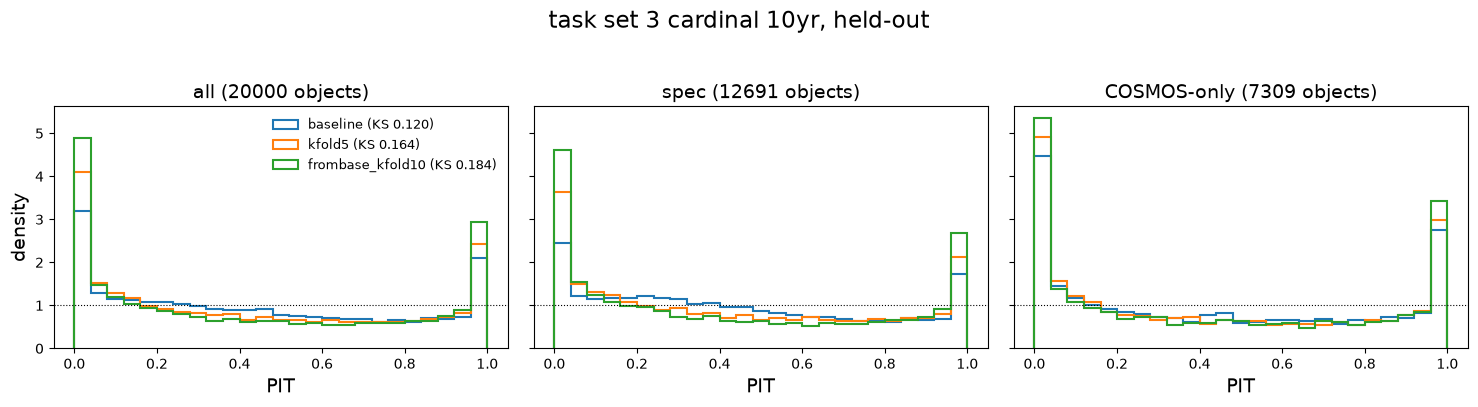

In [7]:
pit_bins = np.linspace(0, 1, 26)
fig, axes = plt.subplots(1, len(subsets), figsize=(5 * len(subsets), 4), sharey=True, squeeze=False)
for ax, subset in zip(axes[0], subsets):
    for name in ARMS:
        ax.hist(pits[(subset, name)], pit_bins, density=True, histtype="step", lw=1.5,
                label=f"{name} (KS {table.loc[(subset, name), 'ks']:.3f})")
    ax.axhline(1, color="k", lw=0.8, ls=":")
    ax.set_title(f"{subset} ({subsets[subset][idx_val].sum()} objects)")
    ax.set_xlabel("PIT")
axes[0, 0].set_ylabel("density")
axes[0, 0].legend(fontsize=9, frameon=False)
fig.suptitle(f"task set {TASKSET} {SIM} {SCENARIO}, held-out", y=1.02)
fig.tight_layout()
plt.show()